In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageStat, ImageOps
import cv2

In [ ]:
import os
import pathlib 
from tqdm import tqdm

In [ ]:
#CARGA DEL DATASET DE IMAGENES VALIDAS 
df_reid_cropped = pd.read_csv('../data/processed/df_cat_reid_validation.csv')
df_reid_cropped_modified = df_reid_cropped.copy()

In [ ]:
PATH_LABELS = "./runs/data/interim/det_26m/labels"
labels = [os.path.basename(f).split('.')[0] for f in os.scandir(PATH_LABELS) if os.path.basename(f).endswith('txt')]

**RECORTE DE LAS IMAGENES, USANDO LAS DETECCIONES DE YOLO26m**

In [ ]:
def crop_yolo_detections(df, label_dir, output_dir, padding=1.1):
    base_out_path = pathlib.Path(output_dir)
    
    for _, row in tqdm(df.iterrows()):

        #EXTRACCIÓN DE LAS DETECCIONES VALIDAS REPORTADAS.
        img_path = pathlib.Path(row['file_path'])
        txt_path = pathlib.Path(label_dir) / f"{row['file_name']}.txt"
        
        if not img_path.exists() or not txt_path.exists():
            continue
            
        data = np.loadtxt(txt_path)
        if data.ndim != 1:
            continue
            
        sub_out_path = base_out_path / str(row['dir_name'])
        sub_out_path.mkdir(parents=True, exist_ok=True)

        #CARGA DE CADA UNA DE LAS IMAGENES USANDO EL MODULO 
        #Image de PIL.
        with Image.open(img_path) as img:
            w, h = img.size
            xc, yc, bw, bh = data[1:5]

            #PADING DE AGREGADO A LAS BOUNDIN BOXES DE YOLO,
            #CON EL OBJETIVO DE PERDER LA MENOR INFORMACION POSIBLE.
            bw_pad = bw * padding
            bh_pad = bh * padding
            
            xmin = int((xc - bw_pad / 2) * w)
            ymin = int((yc - bh_pad / 2) * h)
            xmax = int((xc + bw_pad / 2) * w)
            ymax = int((yc + bh_pad / 2) * h)

            #RECORTE Y SUBIDA DE LAS IMAGENES PROCESADAS.
            cropped = img.crop((max(0, xmin), max(0, ymin), min(w, xmax), min(h, ymax)))
            cropped.save(sub_out_path / f"{row['file_name']}.jpg")

In [7]:
crop_yolo_detections(df=df_reid_cropped_modified, label_dir=PATH_LABELS, output_dir='../data/processed/cropped')

12872it [13:37, 15.74it/s] 


**EDA RECORTE**

**FUNCION DE LISTADO DE IMAGENES REUTILIZADO DEL EDA DE LA PRIMERA ENTREGA**

In [8]:
def list_files(path, dict_images=None):
    if dict_images is None:
        dict_images = {
            "file_path": [],
            "dir_name": [], 
            "file_name": [],
            "format": [],
            "resolution": [],
            "height": [],
            "width": [],
            "ratio": [],
            "mode": [],
            "file_size_mb": [],
            "brightness": []
        }

    base_path = pathlib.Path(path)

    for entry in os.scandir(base_path): 
        entry_path = pathlib.Path(entry.path)

        if entry.is_file():
            if not entry.name.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue
            
            actual_dir = entry_path.parent.name.split('_')[0]
            file_name = entry_path.stem
            file_size = entry.stat().st_size

            try:
                with Image.open(entry.path) as img:
                    img_width, img_height = img.size
                    if img_height == 0:
                        continue

                    stat = ImageStat.Stat(img.convert("L"))
                    img_brightness = round(
                        stat.mean[0], 2
                    )

                    img_format, img_mode, img_resolution, img_ratio = img.format, img.mode, img_width*img_height, round(img_width/img_height, 2)

                    dict_images["file_path"].append(entry_path.as_posix())
                    dict_images["dir_name"].append(actual_dir)
                    dict_images["file_name"].append(file_name)
                    dict_images["format"].append(img_format)
                    dict_images["height"].append(img_height)
                    dict_images["width"].append(img_width)
                    dict_images["resolution"].append(img_resolution)
                    dict_images["ratio"].append(img_ratio)
                    dict_images["mode"].append(img_mode)
                    dict_images["file_size_mb"].append(file_size / (1024**2))
                    dict_images["brightness"].append(img_brightness)

            except Exception as e:
                continue

        elif entry.is_dir():
            dict_images = list_files(entry_path, dict_images)

    return dict_images

In [9]:
reid_cropped_analysis = list_files("../data/processed/cropped")

In [ ]:
#DEFINICION DE LA COL ORIENTATION USANDO LAS RELACIONES DE ASPECT RATIO.
df_reid_cropped_analysis = pd.DataFrame(reid_cropped_analysis)
df_reid_cropped_analysis["orientation"] = df_reid_cropped_analysis["ratio"].apply(
    lambda x: "horizontal" if x > 1.03
    else "vertical" if x < 0.97
    else "cuadrada"
)
df_reid_cropped_analysis_modified = df_reid_cropped_analysis.copy()

In [11]:
df_reid_cropped_analysis_modified.head()

,file_path,dir_name,file_name,format,resolution,height,width,ratio,mode,file_size_mb,brightness,orientation
0,../data/processed/cropped/1/0001_000.jpg,1,0001_000,JPEG,5015952,2448,2049,0.84,RGB,0.600858,63.59,vertical
1,../data/processed/cropped/1/0001_001.jpg,1,0001_001,JPEG,6186180,2266,2730,1.20,RGB,0.644691,62.71,horizontal
2,../data/processed/cropped/1/0001_002.jpg,1,0001_002,JPEG,5334504,2373,2248,0.95,RGB,0.543337,114.25,vertical
3,../data/processed/cropped/1/0001_003.jpg,1,0001_003,JPEG,6358008,2292,2774,1.21,RGB,0.685678,109.35,horizontal
4,../data/processed/cropped/1/0001_004.jpg,1,0001_004,JPEG,5631128,2372,2374,1.00,RGB,0.620113,109.72,cuadrada


In [ ]:
#SUBIDA DEL DATASET CON LAS RUTAS Y LAS COLUMNAS PARA ANLISIS DE LAS IMAGENES RECORTADAS.
df_reid_cropped_analysis_modified.to_csv(
    '../data/processed/df_reid_cropped.csv', index=False
)

In [ ]:
#CANTIDAD DE IMAGENES VALIDAS DETECTADAS POR YOLO
len(df_reid_cropped_analysis_modified)

10524

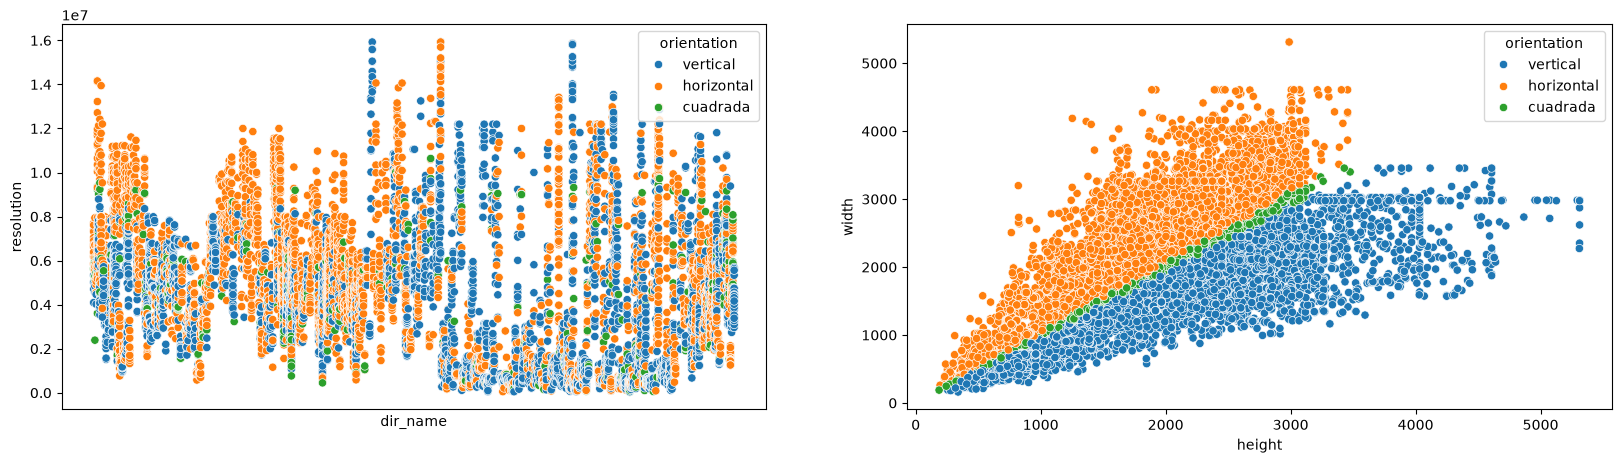

In [14]:
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_reid_cropped_analysis_modified,
    x='dir_name',
    y='resolution',
    hue='orientation')
plt.xticks([])

plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df_reid_cropped_analysis_modified,
    x='height',
    y='width',
    hue='orientation')
plt.show()

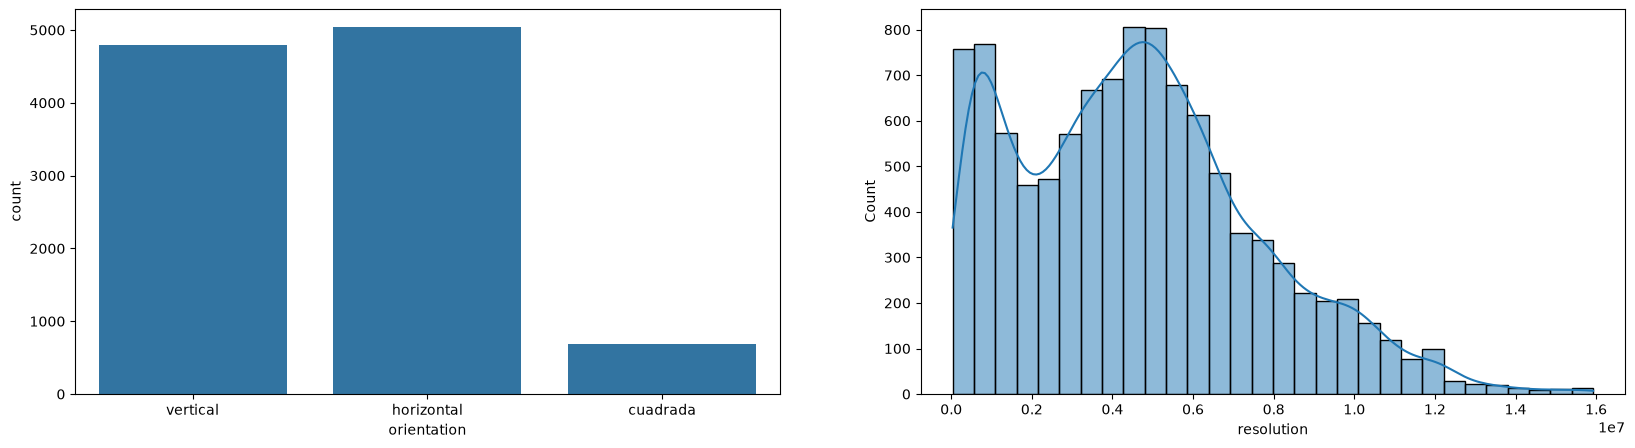

In [15]:
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
sns.countplot(
    data=df_reid_cropped_analysis_modified,
    x='orientation'
    )
plt.subplot(1, 2, 2)
sns.histplot(
    data=df_reid_cropped_analysis_modified,
    x='resolution',
    bins=30,
    kde=True
    )
plt.show()

**REDIMENSIONAMIENTO DE LAS IMAGENES A UN TAMAÑO PREESTABLECIDO DE 300X300**
**DEJANDO UN PADDING EXTRA PARA RESPETAR LA ORIENTACIÓN ORIGINAL DE LA IMAGEN RECORTADA**

In [ ]:
output_dir = pathlib.Path('../data/processed/resized')
for i, row in tqdm(df_reid_cropped_analysis_modified.iterrows(), total=len(df_reid_cropped_analysis_modified)):
    path = row['file_path']
    id = str(row['dir_name'])
    file_name = row['file_name']
    with Image.open(path) as img:
        #CONVERSION DE LA IMAGEN RECORTADA A RGB 
        #PARA MANEJO DE POSIBLES ERRORES CON OTROS FORMATOS.
        img = img.convert("RGB")

        img_resized = ImageOps.pad(
            img, #IMAGEN A REDIMENSIONAR
            (300, 300), #TAMAÑO FINAL DE LA IMAGEN
            method=Image.Resampling.LANCZOS, #PADDING AGREGADO A LA IMAGEN
            color=(0, 0, 0) #COLOR DE PADDIN
        )

        target_path = output_dir/id
        target_path.mkdir(parents=True, exist_ok=True)

        #SUBIDA DE LAS IMAGENES A LA CARPETA /data/processed/resized
        #DONDE SE CREA UNA CARPETA POR INDIVIDUO
        output_path = f'{target_path/file_name}.jpg'
        img_resized.save(output_path)

100%|██████████| 10524/10524 [19:21<00:00,  9.06it/s]


**LISTADO DE LAS RUTAS DE LAS IMAGENES REDIMENSIONADAS**

In [17]:
def list_files_resized(path, dict_images=None):
    if dict_images is None:
        dict_images = {
            "file_path": [],
            "dir_name": [], 
            "file_name": []
        }

    base_path = pathlib.Path(path)

    for entry in os.scandir(base_path): 
        entry_path = pathlib.Path(entry.path)

        if entry.is_file():
            if not entry.name.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue
            
            actual_dir = entry_path.parent.name.split('_')[0]
            file_name = entry_path.stem
    
            dict_images["file_path"].append(entry_path.as_posix())
            dict_images["dir_name"].append(actual_dir)
            dict_images["file_name"].append(file_name)
                    

        elif entry.is_dir():
            dict_images = list_files_resized(entry_path, dict_images)

    return dict_images

In [ ]:
#SUBIDA DEL DATASET QUE REPORTA LAS IMAGENES REDIMENSIONADAS
df_reid_cat_resized = pd.DataFrame(list_files_resized('../data/processed/resized'))
df_reid_cat_resized.to_csv(
    '../data/processed/df_reid_resized.csv', index=False
)